# Run noise on real data: how much the score moves when nothing changes

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/model_comparison/model_comparison_run_noise.ipynb)

A model is trained, scored on a test set and compared with another one. Part of the difference is
the test rows, and McNemar's test or an interval covers that part. The other part is the run
itself: the seed that drives subsampling, feature sampling, tree permutations or weight
initialisation. This notebook measures that second part on real datasets with real models, and
then follows it into a hyperparameter search, where the winner is the best of many noisy scores.
Nothing here is simulated.

## Design

Fixed before the experiments ran. Anything changed afterwards is listed under Deviations at the end.

**Definitions.** A *run* is one trained model. A *seed* is the model's `random_seed` with the
training rows and the hyperparameters held fixed. Runs that are compared are scored on the same
test rows. Accuracy is the metric throughout.

**Data.**

- *SmallDataBenchmarks*, the 108 datasets of `results/catboost_retune_calibration.csv` at commit
  `0227b62`, the same set as the decision notebook. Datasets above 10 000 rows are cut to 10 000
  with `default_rng(0)`, the benchmark's own rule; categoricals are one-hot encoded. The test set
  is `min(1000, n // 2)` random rows and the rest is training data, so only the datasets with at
  least 2000 rows get the full 1000 test rows. Siblings are merged into 95 families with the
  decision notebook's rule.
- *Large OpenML datasets*, binary, at least 30 000 rows, pinned by ID: adult 1590, electricity
  151, bank-marketing 1461, default-of-credit-card-clients 42477, higgs 23512, covertype 44121
  (the binary version), jannis 44131 (the binary version; 41168 has four classes), MiniBooNE 41150,
  road-safety 45038. Not used: nomao 1486, whose pilot accuracy of 0.96 is too close to 1;
  MagicTelescope, with 19 020 rows; albert, which OpenML did not serve. One-hot encoding.

**Models.** Four families, one size and one number of iterations each, CPU, one thread per fit:

- CatBoost with default parameters (1000 iterations, depth 6);
- CatBoost with subsampling: `bootstrap_type="Bernoulli", subsample=0.8, rsm=0.8`;
- LightGBM with bagging: 500 trees, `learning_rate=0.05, num_leaves=31, bagging_fraction=0.8,
  bagging_freq=1, feature_fraction=0.8, deterministic=True`;
- a scikit-learn MLP, two hidden layers of 64, exactly 100 epochs, after median imputation and
  standardisation.

Before anything else: the same seed must give bit-identical predictions, within one process and
across two processes. Otherwise a difference between seeds could not be told apart from a
difference between repeats of one seed.

**Experiment A: seed noise and false alarms.** For every dataset and family the training rows are
fixed and K = 40 seeds (0 to 39) are trained. On SmallDataBenchmarks there is one test set per
dataset. On the large datasets the training set is 5000 random rows and the test pool is 5000
other rows, cut into disjoint blocks of 200 (25 blocks), 1000 (5) and 5000 (1); every block is a
test set of its own, and a dataset's value at a test size is the mean over its blocks.

- A1. SD of accuracy across the 40 seeds, per test set; at a test size, the root of the mean
  variance over blocks. This SD includes how the row sample interacts with the seed. The seed's
  effect on the accuracy over the whole population of rows is estimated separately: split the test
  rows into two random halves, take the covariance across seeds of the two half-accuracies (rows
  in different halves are independent, so only the seed's shift is shared), average over 50
  random halvings, clip at zero, take the root.
- A2. For each of the 780 pairs of seeds: the share of test rows where one run is right and the
  other is wrong, and the accuracy difference. Reported: the mean share, the root mean square of
  the difference (its SD, since the mean is zero by symmetry), and the share of pairs whose
  difference is at least one accuracy point in either direction. A "gain" of at least one point
  for a given order of the two runs is half of that share.
- A3. McNemar's exact two-sided test on every pair, `binomtest` on the discordant rows with
  p = 0.5, computed in its closed form and checked against `scipy.stats.binomtest`. The false alarm
  rate is the share of pairs with p < 0.05. Over all 780 pairs this equals the average over every
  way to split the 40 seeds into 20 disjoint pairs.
- A4. Five seeds against five: 1000 random draws of 10 of the 40 seeds per test set, split five
  and five, Welch's t-test (`ttest_ind(equal_var=False)`) on the ten accuracies. The false alarm
  rate is the share with p < 0.05; a draw where all ten accuracies are equal has no p-value and
  counts as no alarm.
- A5. A1 to A4 at 200, 1000 and 5000 test rows, on the large datasets.

**Experiment B: a hyperparameter search.** The large datasets except MiniBooNE, which is left out
for time. Per dataset a fixed random set H of 20 000 rows stands in for the population and is
never used by the search. From the remaining pool every study draws afresh a training set of 5000
rows and three sets of 1000: V (scores every trial of the study), V2 and V3. For the same study
number, TPE and Random get the same draw. Optuna's `TPESampler(seed=r)` and `RandomSampler(seed=r)`
with default settings, 200 trials per study, R = 10 studies per dataset and sampler. The model is
CatBoost with 300 iterations and `bootstrap_type="Bayesian"` (needed for `bagging_temperature`),
searched over depth 4 to 10, `learning_rate` 0.01 to 0.3 (log), `l2_leaf_reg` 1 to 30 (log),
`random_strength` 0 to 10 and `bagging_temperature` 0 to 5. Every trial has its own seed. Per
trial: the parameters, the seed, the accuracy on V and the accuracy of the same fitted run on H.

The results for T = 1, 3, 7, 15, 30, 50, 100, 200 are prefixes of the same study. The winner of a
prefix is the trial with the highest accuracy on V, the earlier trial on ties.

- B1. Inflation: the winner's accuracy on V minus the same run's accuracy on H.
- B2. Real gain: the winner's accuracy on H minus the mean accuracy on H over the prefix.
- B3. Loss: the best accuracy on H in the prefix minus the winner's accuracy on H.
- B4. From 50 to 200 trials: the change in the reported score (the winner's V), in the winner's
  accuracy on H, and in B2.
- B5. The fix, for T of 7 and up: the five best trials of the prefix by V are trained again with
  five fresh seeds each, scored on V2, and the one with the highest mean V2 is chosen. Its loss as
  in B3, against the H of its search run; the same loss with the mean H of the fresh runs for both
  the chosen trial and the plain winner; and the inflation of the chosen trial's mean V2 and mean
  V3, each minus its mean H over the fresh runs. V3 is the number to report.
- B6. The spread of configurations: the SD of accuracy on H over the 200 trials of a study, TPE
  against Random. It includes the seed; the seed's share is removed with the variance of H across
  the fresh runs of the same configuration in B5.

A dataset's value is the mean over its R studies.

**Summaries.** The dataset is the unit. Every metric is computed per dataset first. On
SmallDataBenchmarks the datasets of a family are averaged into one value, so the summary runs over
95 families. The summary is the median over datasets (or families) with a 90% percentile
bootstrap interval over datasets (or families), 10 000 resamples.

**Budget.** Pilot: one seed of every experiment A task and one search fit per depth and dataset,
timed with seven fits side by side on a machine shared with another job; every fit uses one
thread, seven at a time, at `nice -n 10`. Experiment A is about 18 700 fits, about 54 500
single-thread seconds, about 2.2 hours on seven workers; one SmallDataBenchmarks dataset (semeion)
takes about 150 seconds per CatBoost fit and sets the tail. Experiment B is about 32 000 search
fits and about 10 000 re-runs, about 3.8 hours if depth is drawn uniformly, more if TPE prefers deep
trees. About 6 hours in total, up to about 8.5 at worst. To keep within roughly 8 hours, B was cut
to 8 datasets with R = 10 rather than 9 datasets.

In [1]:
import io, json, subprocess, sys, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)

RECOMPUTE = False  # True re-runs every fit: about 6 hours on 7 cores, from a clone of the repository
REPO = Path("../..")
if RECOMPUTE:
    for mode in ("determinism", "time", "a", "b", "collect"):
        subprocess.run([sys.executable, str(REPO / "scripts/run_noise_experiment.py"), mode], check=True)

# the cache the script wrote, pinned to the commit that added it
DATA_COMMIT = "c3cedc47a7295cb50759886b4961b15fdff30682"
LOCAL = REPO / "results/model_comparison/run_noise"
URL = f"https://raw.githubusercontent.com/firefly1248/demo-notebooks/{DATA_COMMIT}/results/model_comparison/run_noise/"

def fetch(name):
    return (LOCAL / name).read_bytes() if LOCAL.exists() else urllib.request.urlopen(URL + name).read()

A = pd.read_parquet(io.BytesIO(fetch("a_correct.parquet")))
A_INFO = pd.read_csv(io.BytesIO(fetch("a_info.csv")))
TRIALS = pd.read_parquet(io.BytesIO(fetch("b_trials.parquet")))
RERUNS = pd.read_parquet(io.BytesIO(fetch("b_reruns.parquet")))
META, DETERMINISM = json.loads(fetch("meta.json")), json.loads(fetch("determinism.json"))
print("run with", META["versions"])
print(f"experiment A: {A_INFO.fits.sum()} fits, {A_INFO.fit_seconds.sum() / 3600:.1f} single-thread hours")
print("this session: numpy", np.__version__, "pandas", pd.__version__, "scipy", scipy.__version__)

run with {'python': '3.12.12', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.0', 'catboost': '1.2.10', 'lightgbm': '4.7.0', 'optuna': '4.9.0'}
experiment A: 18720 fits, 15.5 single-thread hours
this session: numpy 2.4.6 pandas 3.0.5 scipy 1.18.1


## Same seed, same predictions?

On three datasets, each family was fitted twice with seed 0 in one worker task, once more in a
second task, and once with seed 1. The first three must agree to the last bit; the fourth shows that
the seed reaches the predictions at all. The check covers one machine and one library stack.

In [2]:
print(pd.DataFrame(DETERMINISM["cases"]).to_string(index=False))

source             dataset       family  same_process_identical  two_processes_identical  max_abs_diff_two_processes  other_seed_rows_changed
   sdb            spambase     catboost                    True                     True                         0.0                   0.0020
   sdb            spambase catboost_sub                    True                     True                         0.0                   0.0050
   sdb            spambase lightgbm_bag                    True                     True                         0.0                   0.0080
   sdb            spambase          mlp                    True                     True                         0.0                   0.0340
   sdb wine-quality-5class     catboost                    True                     True                         0.0                   0.0630
   sdb wine-quality-5class catboost_sub                    True                     True                         0.0                   0.0740
   sdb

## Experiment A: what 40 seeds of one procedure do

The cache holds, for every dataset, family, test row and seed, whether the run got the row right.
Everything below is computed from that matrix. First the closed form of McNemar's exact test,
checked against `scipy.stats.binomtest`.

In [3]:
ALPHA, N_SPLITS, N_HALVES, N_BOOT = 0.05, 1000, 50, 10_000
SIZES = (200, 1000, 5000)
FAMILIES = ["catboost", "catboost_sub", "lightgbm_bag", "mlp"]

def mcnemar_p(b, c):
    # two-sided exact McNemar: binomial test of b against b + c at p = 0.5
    return np.minimum(1, 2 * stats.binom.cdf(np.minimum(b, c), b + c, 0.5))

check = np.random.default_rng(1).integers(0, 60, (2000, 2))
scipy_p = [stats.binomtest(b, b + c, 0.5).pvalue if b + c else 1.0 for b, c in check]
print("largest difference from binomtest:", np.abs(mcnemar_p(check[:, 0], check[:, 1]) - scipy_p).max())

largest difference from binomtest: 6.661338147750939e-16


In [4]:
def block_metrics(C, rng):
    # C: test rows x seeds, True where the run is right; one test set
    m, k = C.shape
    acc = C.mean(axis=0)
    Ci = C.astype(np.int32)
    hits = Ci.sum(axis=0)                  # Welch on counts: equal runs give exactly zero variance
    b = Ci.T @ (1 - Ci)                    # b[i, j]: rows run i gets right and run j gets wrong
    iu = np.triu_indices(k, 1)             # the 780 pairs
    bi, ci = b[iu], b.T[iu]
    diff = acc[iu[0]] - acc[iu[1]]
    draws = np.array([rng.permutation(k)[:10] for _ in range(N_SPLITS)])
    # disjoint units for the Wilson intervals: pairs (0, 1), (2, 3), ... and four groups of 5 against 5
    disjoint = np.arange(0, k, 2)
    groups = np.arange(k).reshape(-1, 10)
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore")    # all ten equal: no p-value, counted as no alarm below
        p_welch = stats.ttest_ind(hits[draws[:, :5]], hits[draws[:, 5:]], axis=1, equal_var=False).pvalue
        p_groups = stats.ttest_ind(hits[groups[:, :5]], hits[groups[:, 5:]], axis=1, equal_var=False).pvalue
    q = C.mean(axis=1)                     # per row, the share of seeds that get it right
    flip_var = (q * (1 - q)).sum() / m ** 2 * k / (k - 1)   # seed variance if rows flipped independently
    return {"acc": acc.mean(), "var_seed": acc.var(ddof=1), "flip_ratio": acc.var(ddof=1) / flip_var if flip_var else np.nan,
            "disagree": ((bi + ci) / m).mean(),
            "msd_pair": (diff ** 2).mean(), "pair_ge_1pp": (np.abs(diff) >= 0.01 - 1e-12).mean(),
            "mcnemar": (mcnemar_p(bi, ci) < ALPHA).mean(),
            "welch": (np.nan_to_num(p_welch, nan=1.0) < ALPHA).mean(),
            "mcnemar_k": (mcnemar_p(b[disjoint, disjoint + 1], b[disjoint + 1, disjoint]) < ALPHA).sum(),
            "mcnemar_n": len(disjoint),
            "welch_k": (np.nan_to_num(p_groups, nan=1.0) < ALPHA).sum(), "welch_n": len(groups)}

def split_half_var(C, rng):
    # seed variance of the accuracy on the population of rows: rows in two disjoint halves are
    # independent, so the covariance across seeds of the two half-accuracies is the seed's shift only
    covs = []
    for _ in range(N_HALVES):
        perm = rng.permutation(len(C))
        h = len(C) // 2
        covs.append(np.cov(C[perm[:h]].mean(0), C[perm[h:]].mean(0))[0, 1])
    return np.mean(covs)

def dataset_metrics(source, C):
    rng = np.random.default_rng(0)
    shift = split_half_var(C, rng)
    out = []
    for size in ((len(C),) if source == "sdb" else SIZES):
        blocks = pd.DataFrame([block_metrics(C[i:i + size], rng) for i in range(0, len(C), size)])
        mean, total = blocks.mean(), blocks.sum()
        out.append({"test_rows": size, "blocks": len(blocks), "acc": mean.acc,
                    "sd_seed": np.sqrt(mean.var_seed), "flip_ratio": mean.flip_ratio, "sd_shift": np.sqrt(max(shift, 0)), "shift_var": shift,
                    "disagree": mean.disagree, "sd_pair": np.sqrt(mean.msd_pair), "pair_ge_1pp": mean.pair_ge_1pp,
                    "mcnemar": mean.mcnemar, "welch": mean.welch,
                    **{c: int(total[c]) for c in ("mcnemar_k", "mcnemar_n", "welch_k", "welch_n")}})
    return out

SEED_COLS = [c for c in A.columns if c.startswith("c")]
rows = []
for (source, dataset, family), g in A.groupby(["source", "dataset", "family"], observed=True):
    for r in dataset_metrics(source, g.sort_values("row")[SEED_COLS].to_numpy()):
        rows.append({"source": source, "dataset": dataset, "family": family, **r})
PER_DATASET = pd.DataFrame(rows)
print(PER_DATASET.groupby(["source", "test_rows"]).size().to_string())

# where all 40 runs are right on exactly the same rows, neither test can fire: leave them out of the rates
IDENTICAL = PER_DATASET.disagree == 0
PER_DATASET.loc[IDENTICAL, ["mcnemar", "welch"]] = np.nan
print("datasets with 40 identical runs, left out of the false alarm rates:")
for fam, names in PER_DATASET[IDENTICAL].groupby("family").dataset:
    print(f"  {fam}: {', '.join(names)}")

source  test_rows
openml  200           36
        1000          36
        5000          36
sdb     25             4
        31             4
        44             4
        50             8
        53             8
        58             4
        63             4
        75             8
        77             4
        80             4
        82             4
        91             4
        97             4
        104            4
        105            4
        107            4
        135            4
        147            4
        153            4
        155            8
        172            4
        174            4
        175            4
        183            4
        200            4
        201            4
        220            8
        231            4
        235            4
        250            8
        270            4
        277            4
        278            4
        284            4
        291            4
        300            4
       

## From datasets to one number

SmallDataBenchmarks holds variants of one problem, cut at different numbers of classes or recorded
in different sessions. They are averaged into one value per family with the decision notebook's
rule. Then every summary is a median over datasets (or families) with a 90% bootstrap interval over
datasets (or families). On SmallDataBenchmarks two versions are shown: all 95 families, whatever
their test size, and only the datasets with the full 1000 test rows. The SDs, the share of pairs a
point apart and the false alarm rates depend on the test size (A5 shows how much), so the second
version is the closer one to the large datasets. It is not the same setting, though: those datasets
are easier (higher accuracy) and train on more rows.

With 8 or 9 large datasets the interval of a median is rough. It cannot reach beyond the second
smallest and second largest value, and its coverage is below the nominal 90%. Read it next to the
per-dataset values.

In [5]:
def median_ci(x, seed=0):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    if len(x) == 0:
        return np.nan, np.nan, np.nan
    boot = np.median(np.random.default_rng(seed).choice(x, (N_BOOT, len(x))), axis=1)
    return np.median(x), *np.percentile(boot, [5, 95])

METRICS_A = ["acc", "sd_seed", "sd_shift", "disagree", "sd_pair", "pair_ge_1pp", "mcnemar", "welch"]
# the decision notebook's rule: strip a trailing class count, session letter+number or sensor index
sdb = PER_DATASET[PER_DATASET.source == "sdb"].assign(
    unit=lambda d: d.dataset.str.replace(r"[-_]?\d+class$", "", regex=True).str.replace(r"-[a-z]*\d+[a-z]*$", "", regex=True))
print(f"{sdb.dataset.nunique()} datasets in {sdb.unit.nunique()} families")
UNITS = {
    "OpenML": PER_DATASET[PER_DATASET.source == "openml"].assign(unit=lambda d: d.dataset),
    "SDB, all": sdb.assign(test_rows=0),
    "SDB, 1000 test rows": sdb[sdb.test_rows == 1000],
}

def summary(frame, metrics, by):
    rows = []
    for key, g in frame.groupby(by):
        r = dict(zip(by, key))
        r["units"] = len(g)
        for m in metrics:
            r[m + "_n"] = int(g[m].notna().sum())
            med, lo, hi = median_ci(g[m])
            r[m] = med
            r[m + "_lo"], r[m + "_hi"] = lo, hi
        rows.append(r)
    return pd.DataFrame(rows)

SUM_A = pd.concat([summary(f.groupby(["unit", "family", "test_rows"])[METRICS_A].mean().reset_index(),
                           METRICS_A, ["family", "test_rows"]).assign(data=name)
                   for name, f in UNITS.items()], ignore_index=True)

def show(frame, metrics, scale, by):
    # median [90% interval], in points or percent
    out = frame[by].copy()
    for m in metrics:
        out[m] = [f"{v * scale:.2f} [{lo * scale:.2f}, {hi * scale:.2f}]"
                  for v, lo, hi in zip(frame[m], frame[m + "_lo"], frame[m + "_hi"])]
    return out.to_string(index=False)

108 datasets in 95 families


### A1. How far the seed moves accuracy

`sd_seed` is the SD of accuracy across the 40 seeds on one test set, in accuracy points. `sd_shift`
is the part that belongs to the seed alone: how far a seed moves the accuracy on the whole
population of rows, from the split-half covariance. Test size 0 marks the SmallDataBenchmarks rows
that mix test sizes. Accuracy is in percent.

In [6]:
print(show(SUM_A, ["acc", "sd_seed", "sd_shift"], 100, ["data", "family", "test_rows", "units"]))

               data       family  test_rows  units                  acc           sd_seed          sd_shift
             OpenML     catboost        200      9 81.06 [77.79, 86.63] 0.66 [0.52, 0.84] 0.00 [0.00, 0.05]
             OpenML     catboost       1000      9 81.06 [77.79, 86.63] 0.29 [0.23, 0.36] 0.00 [0.00, 0.05]
             OpenML     catboost       5000      9 81.06 [77.79, 86.63] 0.14 [0.11, 0.17] 0.00 [0.00, 0.05]
             OpenML catboost_sub        200      9 81.07 [77.72, 86.70] 0.68 [0.53, 0.88] 0.00 [0.00, 0.02]
             OpenML catboost_sub       1000      9 81.07 [77.72, 86.70] 0.30 [0.24, 0.39] 0.00 [0.00, 0.02]
             OpenML catboost_sub       5000      9 81.07 [77.72, 86.70] 0.15 [0.10, 0.18] 0.00 [0.00, 0.02]
             OpenML lightgbm_bag        200      9 80.37 [77.22, 85.66] 0.89 [0.82, 1.24] 0.08 [0.00, 0.09]
             OpenML lightgbm_bag       1000      9 80.37 [77.22, 85.66] 0.41 [0.33, 0.56] 0.08 [0.00, 0.09]
             OpenML lightgbm

Why the shift can be near zero while the SD on a test set is not: if every unstable row flipped
independently between seeds, the variance of accuracy across seeds would be the sum of the per-row
variances over the squared test size. `flip_ratio` is the observed variance over that figure. With
test rows drawn at random its expected value is at least 1, and it is above 1 by the part of the
variance that comes from a shift of the population accuracy. Values a little below 1 are noise.
The first table below is a median over datasets (OpenML, 1000 test rows) or families
(SmallDataBenchmarks); the second is the share of those units where the covariance is not positive.

In [7]:
by_unit = (pd.concat([UNITS["OpenML"][UNITS["OpenML"].test_rows == 1000], UNITS["SDB, all"]])
           .assign(neg=lambda d: d.shift_var <= 0)
           .groupby(["source", "unit", "family"])[["flip_ratio", "neg"]].mean())
print(by_unit.flip_ratio.groupby(["source", "family"]).median().round(2).unstack().to_string())
print()
print("share where the split-half covariance is not positive (sd_shift clipped to 0):")
print(by_unit.neg.groupby(["source", "family"]).mean().round(2).unstack().to_string())

family  catboost  catboost_sub  lightgbm_bag   mlp
source                                            
openml      0.93          0.93          0.98  1.07
sdb         1.01          1.00          1.02  1.19

share where the split-half covariance is not positive (sd_shift clipped to 0):
family  catboost  catboost_sub  lightgbm_bag   mlp
source                                            
openml      0.56          0.67          0.44  0.00
sdb         0.49          0.47          0.49  0.33


### A2. Two runs of the same procedure

For every pair of seeds: the share of test rows where one run is right and the other wrong, the SD
of their accuracy difference in points, and the share of pairs at least one point apart in either
direction (half of it is a "gain" of a point or more in a given order).

In [8]:
print(show(SUM_A, ["disagree", "pair_ge_1pp"], 100, ["data", "family", "test_rows", "units"]))
print()
print(show(SUM_A, ["sd_pair"], 100, ["data", "family", "test_rows", "units"]))

               data       family  test_rows  units           disagree          pair_ge_1pp
             OpenML     catboost        200      9  1.75 [1.13, 3.14] 41.33 [29.13, 51.83]
             OpenML     catboost       1000      9  1.75 [1.13, 3.14]    2.18 [0.28, 5.72]
             OpenML     catboost       5000      9  1.75 [1.13, 3.14]    0.00 [0.00, 0.00]
             OpenML catboost_sub        200      9  1.88 [1.17, 3.31] 42.48 [29.02, 53.94]
             OpenML catboost_sub       1000      9  1.88 [1.17, 3.31]    2.64 [0.54, 8.36]
             OpenML catboost_sub       5000      9  1.88 [1.17, 3.31]    0.00 [0.00, 0.00]
             OpenML lightgbm_bag        200      9  3.17 [2.64, 5.99] 53.44 [50.46, 66.30]
             OpenML lightgbm_bag       1000      9  3.17 [2.64, 5.99]  10.03 [4.13, 22.28]
             OpenML lightgbm_bag       5000      9  3.17 [2.64, 5.99]    0.00 [0.00, 0.64]
             OpenML          mlp        200      9 8.26 [7.15, 17.97] 71.29 [68.18, 80.96]

### A3 and A4. False alarms

McNemar's test on one pair of seeds, and Welch's test on five seeds against five. A false alarm
here is a test that declares two runs of one procedure different. Rates in percent; the nominal rate
is 5%. Where the seed does shift the population accuracy (the MLP), a rejection of McNemar's test is
partly a correct statement about those two fitted models, and still a false statement about the
procedure. Datasets where all 40 runs are identical are left out (listed above), so `units` here
counts only the ones that remain.

In [9]:
print(show(SUM_A, ["mcnemar", "welch"], 100, ["data", "family", "test_rows", "mcnemar_n"]).replace("mcnemar_n", "    units"))

               data       family  test_rows      units            mcnemar             welch
             OpenML     catboost        200          9  0.30 [0.05, 0.88] 4.32 [4.22, 4.38]
             OpenML     catboost       1000          9  1.92 [1.54, 2.90] 4.24 [4.18, 4.54]
             OpenML     catboost       5000          9  3.46 [1.54, 5.13] 4.30 [4.10, 4.60]
             OpenML catboost_sub        200          9  0.45 [0.06, 1.02] 4.50 [4.31, 4.56]
             OpenML catboost_sub       1000          9  2.51 [2.18, 3.05] 4.66 [4.34, 4.76]
             OpenML catboost_sub       5000          9  2.82 [2.18, 4.49] 4.30 [3.90, 4.60]
             OpenML lightgbm_bag        200          9  1.58 [0.97, 2.28] 4.48 [4.43, 4.48]
             OpenML lightgbm_bag       1000          9  3.64 [1.85, 3.69] 4.42 [4.20, 4.56]
             OpenML lightgbm_bag       5000          9  5.00 [1.79, 5.51] 4.30 [3.80, 4.80]
             OpenML          mlp        200          9  3.33 [2.43, 3.79] 4.46 [

Per dataset, with a 95% Wilson interval. The interval needs independent units, so it counts disjoint
ones only: the 20 pairs (0, 1), (2, 3), ... and the four groups of five against five, in every test
block. Units in one block share the test rows, and units in different blocks share the seeds, so
even these are not fully independent and the interval is a rough guide. The bootstrap over datasets
above is the summary to read.

In [10]:
def wilson(k, n, z=stats.norm.ppf(0.975)):
    # wilson_lower copied from model_comparison_proportion_bounds, extended to both ends
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

per = PER_DATASET[(PER_DATASET.source == "openml") & (PER_DATASET.test_rows == 1000)].copy()
for t in ("mcnemar", "welch"):
    lo, hi = wilson(per[t + "_k"], per[t + "_n"])
    per[t + " disjoint"] = [f"{k}/{n} [{a:.0%}, {b:.0%}]" for k, n, a, b in zip(per[t + "_k"], per[t + "_n"], lo, hi)]
print(per[["dataset", "family", "mcnemar", "mcnemar disjoint", "welch", "welch disjoint"]]
      .round(3).to_string(index=False))

       dataset       family  mcnemar mcnemar disjoint  welch welch disjoint
         adult     catboost    0.012   2/100 [1%, 7%]  0.045 1/20 [1%, 24%]
         adult catboost_sub    0.028  4/100 [2%, 10%]  0.047 3/20 [5%, 36%]
         adult lightgbm_bag    0.013   1/100 [0%, 5%]  0.048 1/20 [1%, 24%]
         adult          mlp    0.042  5/100 [2%, 11%]  0.049 1/20 [1%, 24%]
bank-marketing     catboost    0.029   3/100 [1%, 8%]  0.042 1/20 [1%, 24%]
bank-marketing catboost_sub    0.015   1/100 [0%, 5%]  0.046 2/20 [3%, 30%]
bank-marketing lightgbm_bag    0.018   2/100 [1%, 7%]  0.046 1/20 [1%, 24%]
bank-marketing          mlp    0.034  6/100 [3%, 12%]  0.051 0/20 [0%, 16%]
     covertype     catboost    0.029   3/100 [1%, 8%]  0.042 0/20 [0%, 16%]
     covertype catboost_sub    0.015  4/100 [2%, 10%]  0.042 2/20 [3%, 30%]
     covertype lightgbm_bag    0.060  5/100 [2%, 11%]  0.042 1/20 [1%, 24%]
     covertype          mlp    0.056   3/100 [1%, 8%]  0.043 1/20 [1%, 24%]
credit-defau

### A5. The test size

On the large datasets the same runs are scored on blocks of 200, 1000 and 5000 rows.

In [11]:
big = PER_DATASET[(PER_DATASET.source == "openml") & (PER_DATASET.test_rows == 5000) & (PER_DATASET.mcnemar > ALPHA)]
print("McNemar above 5% at 5000 rows, by dataset (flip_ratio above 1 means the seed shifts many rows the same way):")
print(big[["dataset", "family", "mcnemar", "flip_ratio"]].round(3).to_string(index=False))
print()
openml = SUM_A[SUM_A.data == "OpenML"]
for fam in FAMILIES:
    print(fam)
    print(show(openml[openml.family == fam],
               ["sd_seed", "sd_pair", "disagree", "pair_ge_1pp", "mcnemar", "welch"], 100, ["test_rows"]))

McNemar above 5% at 5000 rows, by dataset (flip_ratio above 1 means the seed shifts many rows the same way):
       dataset       family  mcnemar  flip_ratio
         adult          mlp    0.112       1.530
bank-marketing     catboost    0.051       1.253
bank-marketing lightgbm_bag    0.103       1.518
bank-marketing          mlp    0.053       1.111
     covertype lightgbm_bag    0.055       1.287
     covertype          mlp    0.129       1.713
credit-default lightgbm_bag    0.077       1.263
credit-default          mlp    0.247       2.763
   electricity     catboost    0.113       1.669
         higgs          mlp    0.090       1.297
        jannis          mlp    0.076       1.249
     miniboone     catboost    0.071       1.329
     miniboone          mlp    0.132       1.795
   road-safety lightgbm_bag    0.055       1.132
   road-safety          mlp    0.095       1.306

catboost
 test_rows           sd_seed           sd_pair          disagree          pair_ge_1pp           m

## Experiment B: the winner of a search

Every study is a sequence of 200 trials; the first T of them are the search with T trials. Per
study and prefix: the winner by V, its inflation (V minus H of the same run), its real gain over
the average trial of the prefix and its loss against the best trial of the prefix, all on H. For
T of 7 and up also the re-run selection: the top five by V, five fresh seeds each, chosen by the
mean on V2.

Three things to keep in mind when reading the tables:

- TPE starts with 10 random trials drawn with the same seed as RandomSampler, so both samplers run
  the same first 10 configurations. Up to T = 7 the two columns differ only by the trials' own
  seeds, and at T = 15 two thirds of the prefix is still shared.
- The two samplers share the training rows, V, V2 and V3 of a study, so their agreement is not an
  independent replication.
- Even an unselected trial reads somewhat differently on V and on H, because V is one draw of 1000
  rows and H is one fixed sample. `inflation_net` takes that offset out: it subtracts the mean V
  minus H over the study's 200 Random trials, which were not selected on anything.

In [12]:
PREFIXES, TOP = META["constants"]["B_PREFIXES"], META["constants"]["B_TOP"]

def study_metrics(trials, reruns):
    trials = trials.sort_values("number").reset_index(drop=True)
    v, h = trials.acc_v.to_numpy(), trials.acc_h.to_numpy()
    fresh = reruns.groupby("number")[["acc_v2", "acc_v3", "acc_h"]].mean()
    seed_var = reruns.groupby("number").acc_h.var(ddof=1).mean()
    rows = []
    for T in PREFIXES:
        w = int(np.argmax(v[:T]))                      # the earlier trial on ties
        best = h[:T].max()
        r = {"T": T, "reported": v[w], "winner_h": h[w], "inflation": v[w] - h[w],
             "gain": h[w] - h[:T].mean(), "loss": best - h[w]}
        if T >= TOP:
            top = trials.iloc[:T].sort_values(["acc_v", "number"], ascending=[False, True]).number.iloc[:TOP]
            pick = fresh.loc[top].acc_v2.idxmax()      # the higher V on ties
            r.update({"loss_rerun": best - trials.acc_h[pick], "same_pick": float(pick == w),
                      "loss_fresh_winner": best - fresh.acc_h[w], "loss_fresh_rerun": best - fresh.acc_h[pick],
                      "infl_v2": fresh.acc_v2[pick] - fresh.acc_h[pick],
                      "infl_v3": fresh.acc_v3[pick] - fresh.acc_h[pick]})
        rows.append(r)
    out = pd.DataFrame(rows)
    out["sd_h"] = h.std(ddof=1)                        # B6, over all 200 trials
    out["seed_var_h"] = seed_var
    return out

RERUNS_BY = dict(list(RERUNS.groupby(["dataset", "sampler", "study"])))
PER_STUDY = pd.concat([study_metrics(g, RERUNS_BY[(d, s, r)])
                       .assign(dataset=d, sampler=s, study=r)
                       for (d, s, r), g in TRIALS.groupby(["dataset", "sampler", "study"])], ignore_index=True)
OFFSET = (TRIALS[TRIALS.sampler == "random"].assign(gap=lambda t: t.acc_v - t.acc_h)
          .groupby(["dataset", "study"]).gap.mean())
PER_STUDY["inflation_net"] = PER_STUDY.inflation - OFFSET.loc[list(zip(PER_STUDY.dataset, PER_STUDY.study))].to_numpy()
PER_STUDY["cut"] = PER_STUDY.loss - PER_STUDY.loss_rerun
PER_STUDY["cut_fresh"] = PER_STUDY.loss_fresh_winner - PER_STUDY.loss_fresh_rerun
B_DATA = PER_STUDY.groupby(["dataset", "sampler", "T"]).mean(numeric_only=True).reset_index()
print(TRIALS.groupby("dataset").study.nunique().rename("studies").to_string())
print(f"{len(TRIALS)} search fits, {len(RERUNS)} re-runs")
print("mean accuracy on H by trial number, points (TPE's later trials are better):")
print((TRIALS.assign(trials=pd.cut(TRIALS.number, [0, 10, 50, 100, 150, 200], right=False))
       .groupby(["sampler", "trials"], observed=True).acc_h.mean().unstack() * 100).round(2).to_string())

dataset
adult             10
bank-marketing    10
covertype         10
credit-default    10
electricity       10
higgs             10
jannis            10
road-safety       10
32000 search fits, 14455 re-runs
mean accuracy on H by trial number, points (TPE's later trials are better):
trials   [0, 10)  [10, 50)  [50, 100)  [100, 150)  [150, 200)
sampler                                                      
random     79.38     79.27      79.26       79.30       79.32
tpe        79.38     80.04      80.31       80.45       80.55


### B1 to B3 by the number of trials

In accuracy points, median over datasets with a 90% interval.

In [13]:
METRICS_B = ["reported", "winner_h", "inflation", "inflation_net", "gain", "loss", "loss_rerun", "loss_fresh_winner",
             "loss_fresh_rerun", "cut", "cut_fresh", "infl_v2", "infl_v3"]
SUM_B = summary(B_DATA, METRICS_B, ["sampler", "T"])
for s in ("tpe", "random"):
    print(s)
    print(show(SUM_B[SUM_B.sampler == s], ["inflation", "inflation_net", "gain", "loss"], 100, ["T", "units"]))

tpe
  T  units          inflation      inflation_net              gain              loss
  1      8 0.30 [-0.11, 0.48] 0.04 [-0.21, 0.15] 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]
  3      8  0.51 [0.35, 0.96]  0.28 [0.24, 0.48] 0.25 [0.11, 0.51] 0.21 [0.15, 0.29]
  7      8  0.67 [0.55, 1.17]  0.52 [0.42, 0.67] 0.67 [0.40, 1.13] 0.26 [0.21, 0.33]
 15      8  0.94 [0.78, 1.36]  0.73 [0.62, 0.85] 0.69 [0.38, 1.08] 0.30 [0.25, 0.36]
 30      8  1.32 [0.92, 1.65]  0.93 [0.80, 1.12] 0.67 [0.23, 0.86] 0.32 [0.28, 0.51]
 50      8  1.35 [1.02, 1.91]  0.96 [0.85, 1.33] 0.66 [0.27, 0.87] 0.33 [0.28, 0.42]
100      8  1.59 [1.24, 2.21]  1.25 [1.02, 1.59] 0.48 [0.21, 0.67] 0.40 [0.38, 0.44]
200      8  1.78 [1.31, 2.32]  1.44 [1.13, 1.70] 0.31 [0.11, 0.50] 0.43 [0.37, 0.50]
random
  T  units          inflation       inflation_net              gain              loss
  1      8 0.21 [-0.06, 0.55] -0.02 [-0.19, 0.11] 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]
  3      8  0.53 [0.29, 0.89]   0.25 [0.21, 0.41] 0.

### B4. From 50 to 200 trials

Per study: how much the reported score (the winner's V) moves, how much the winner's accuracy on H
moves, and how much the real gain moves. Points.

In [14]:
wide = PER_STUDY.pivot_table(index=["dataset", "sampler", "study"], columns="T",
                             values=["reported", "winner_h", "gain"])
step = pd.DataFrame({k: wide[k][200] - wide[k][50] for k in ("reported", "winner_h", "gain")}).reset_index()
SUM_B4 = summary(step.groupby(["dataset", "sampler"]).mean(numeric_only=True).reset_index(),
                 ["reported", "winner_h", "gain"], ["sampler"])
print(show(SUM_B4, ["reported", "winner_h", "gain"], 100, ["sampler", "units"]))

sampler  units          reported           winner_h                 gain
 random      8 0.28 [0.21, 0.32] 0.03 [-0.03, 0.10]   0.04 [-0.02, 0.10]
    tpe      8 0.48 [0.28, 0.61]  0.08 [0.04, 0.17] -0.28 [-0.46, -0.15]


### B4b. Gain over the first trial, reported and held-out

The same winner, measured against the first trial of its own search, on the two sets: the winner's V
minus the first trial's V (what the search reports), and the winner's H minus the first trial's H
(what a fresh set shows). Both start at zero for one trial, so the offset of the V draw cancels. Per
study, then the mean per dataset, then the median over the 8 datasets, as above. Points. This is the
panel B of the post figure.

In [15]:
first = PER_STUDY[PER_STUDY["T"] == 1].set_index(["dataset", "sampler", "study"])[["reported", "winner_h"]]
up = PER_STUDY.join(first, on=["dataset", "sampler", "study"], rsuffix="_1")
up["reported_up"] = up.reported - up.reported_1
up["winner_h_up"] = up.winner_h - up.winner_h_1
B_DATA_UP = up.groupby(["dataset", "sampler", "T"])[["reported_up", "winner_h_up"]].mean().reset_index()
SUM_UP = summary(B_DATA_UP, ["reported_up", "winner_h_up"], ["sampler", "T"])
for s in ("tpe", "random"):
    print(s)
    print(show(SUM_UP[SUM_UP.sampler == s], ["reported_up", "winner_h_up"], 100, ["T", "units"]))
at200 = B_DATA_UP[B_DATA_UP["T"] == 200].groupby("sampler").apply(
    lambda g: int((g.reported_up > g.winner_h_up).sum()), include_groups=False)
print("datasets where the reported gain exceeds the held-out gain at 200 trials, of 8:", at200.to_dict())

tpe
  T  units       reported_up       winner_h_up
  1      8 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]
  3      8 0.60 [0.38, 0.97] 0.23 [0.15, 0.40]
  7      8 1.03 [0.62, 1.54] 0.33 [0.27, 0.77]
 15      8 1.47 [0.84, 2.07] 0.51 [0.32, 1.03]
 30      8 1.83 [0.95, 2.56] 0.66 [0.31, 1.10]
 50      8 2.08 [1.07, 2.98] 0.82 [0.43, 1.31]
100      8 2.45 [1.17, 3.35] 0.89 [0.47, 1.35]
200      8 2.75 [1.32, 3.55] 0.99 [0.45, 1.39]
random
  T  units       reported_up       winner_h_up
  1      8 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]
  3      8 0.75 [0.50, 1.04] 0.36 [0.28, 0.52]
  7      8 0.96 [0.69, 1.50] 0.45 [0.38, 0.68]
 15      8 1.25 [0.92, 1.82] 0.61 [0.46, 0.95]
 30      8 1.56 [1.03, 2.05] 0.55 [0.39, 1.02]
 50      8 1.72 [1.10, 2.32] 0.71 [0.37, 1.20]
100      8 1.85 [1.15, 2.46] 0.66 [0.44, 1.25]
200      8 1.99 [1.28, 2.68] 0.80 [0.34, 1.17]
datasets where the reported gain exceeds the held-out gain at 200 trials, of 8: {'random': 8, 'tpe': 8}


### B5. Re-running the top five

`loss` is the plain winner's, `loss_rerun` the re-run choice's, both against the best trial of the
prefix on H and with the H of the search run. The two `fresh` columns measure the same with the
mean H over the five fresh runs of each, which takes the search run's own seed out. `cut` and
`cut_fresh` are the paired differences, plain winner minus re-run choice, per study and then per
dataset; the count is the number of datasets where the cut is positive. `infl_v2` and `infl_v3` are
the inflation of the chosen trial's mean on V2 (where it was chosen) and on V3 (fresh rows, used for
no choice, so its expected value is zero; what remains is the offset of the V3 draw, the same kind
as `inflation` at T = 1). Points.

The re-run is not free: at a given T it costs 25 more fits and two more sets of 1000 labelled rows,
V2 to choose and V3 to report.

In [16]:
positive = B_DATA[B_DATA["T"] >= 7].groupby(["sampler", "T"])[["cut", "cut_fresh"]].agg(lambda c: (c > 0).sum())
for s in ("tpe", "random"):
    print(s)
    tab = SUM_B[(SUM_B.sampler == s) & (SUM_B["T"] >= 7)]
    print(show(tab, ["loss", "loss_rerun", "loss_fresh_winner", "loss_fresh_rerun"], 100, ["T"]))
    paired = show(tab, ["cut", "cut_fresh", "infl_v2", "infl_v3"], 100, ["T"]).splitlines()
    counts = [f"{a} and {b} of {B_DATA.dataset.nunique()}" for a, b in positive.loc[s].astype(int).itertuples(index=False)]
    print("\n".join([paired[0] + "  datasets with a positive cut, fresh cut"] + [l + "  " + c for l, c in zip(paired[1:], counts)]))
print("share of studies where the re-run picks the plain winner:")
print(PER_STUDY[PER_STUDY["T"] >= 7].groupby(["sampler", "T"]).same_pick.mean().unstack().round(2).to_string())

tpe
  T              loss        loss_rerun loss_fresh_winner  loss_fresh_rerun
  7 0.26 [0.21, 0.33] 0.10 [0.07, 0.17] 0.28 [0.23, 0.34] 0.11 [0.08, 0.22]
 15 0.30 [0.25, 0.36] 0.24 [0.11, 0.36] 0.31 [0.27, 0.38] 0.23 [0.13, 0.32]
 30 0.32 [0.28, 0.51] 0.23 [0.18, 0.24] 0.37 [0.32, 0.58] 0.24 [0.16, 0.30]
 50 0.33 [0.28, 0.42] 0.25 [0.18, 0.32] 0.35 [0.29, 0.43] 0.26 [0.20, 0.34]
100 0.40 [0.38, 0.44] 0.33 [0.28, 0.42] 0.43 [0.35, 0.49] 0.33 [0.28, 0.39]
200 0.43 [0.37, 0.50] 0.40 [0.31, 0.48] 0.48 [0.35, 0.53] 0.38 [0.33, 0.46]
  T                cut          cut_fresh            infl_v2            infl_v3  datasets with a positive cut, fresh cut
  7 0.14 [-0.02, 0.23] 0.17 [-0.02, 0.21]  0.32 [0.07, 0.55] 0.15 [-0.18, 0.27]  5 and 5 of 8
 15 0.09 [-0.06, 0.18] 0.07 [-0.01, 0.21]  0.35 [0.08, 0.60] 0.26 [-0.20, 0.30]  5 and 6 of 8
 30  0.13 [0.09, 0.23]  0.19 [0.15, 0.25]  0.33 [0.01, 0.44] 0.16 [-0.18, 0.30]  8 and 8 of 8
 50  0.10 [0.01, 0.15]  0.11 [0.08, 0.13] 0.34 [-0.07, 0.43] 

### B6. How much configurations differ

The SD of accuracy on H over the 200 trials of a study includes each trial's own seed. Removing
the seed variance, measured across the fresh runs of the same configuration, leaves the spread of
the configurations themselves. The seed variance comes from the re-run configurations only, the best
by V, and the search model (300 iterations, the Bayesian bootstrap, `random_strength` up to 10) is
not the default CatBoost of experiment A, so its seed SD here need not match A1. Points.

How well V ranks the trials: the Spearman correlation between V and H over the 200 trials of a
study, and over the 40 trials with the highest V only, where the winner is picked. Mean over
studies, median over datasets.

In [17]:
b6 = PER_STUDY[PER_STUDY["T"] == 200].assign(
    sd_config=lambda d: np.sqrt(np.clip(d.sd_h ** 2 - d.seed_var_h, 0, None)), sd_seed=lambda d: np.sqrt(d.seed_var_h))
SUM_B6 = summary(b6.groupby(["dataset", "sampler"]).mean(numeric_only=True).reset_index(),
                 ["sd_h", "sd_seed", "sd_config"], ["sampler"])
print(show(SUM_B6, ["sd_h", "sd_seed", "sd_config"], 100, ["sampler", "units"]))
def spearman(t):
    return stats.spearmanr(t.acc_v, t.acc_h)[0]

by_study = TRIALS.groupby(["dataset", "sampler", "study"])
for name, rho in (("all 200 trials", by_study.apply(spearman)),
                  ("top 40 by V", by_study.apply(lambda t: spearman(t.nlargest(40, "acc_v"))))):
    print(f"Spearman of V and H, {name}:", rho.groupby(["dataset", "sampler"]).mean().groupby("sampler").median().round(2).to_dict())

sampler  units              sd_h           sd_seed         sd_config
 random      8 0.73 [0.55, 0.98] 0.15 [0.08, 0.17] 0.71 [0.54, 0.96]
    tpe      8 0.60 [0.36, 0.72] 0.15 [0.08, 0.17] 0.58 [0.35, 0.69]


Spearman of V and H, all 200 trials: {'random': 0.68, 'tpe': 0.52}
Spearman of V and H, top 40 by V: {'random': 0.28, 'tpe': 0.11}


## Figures

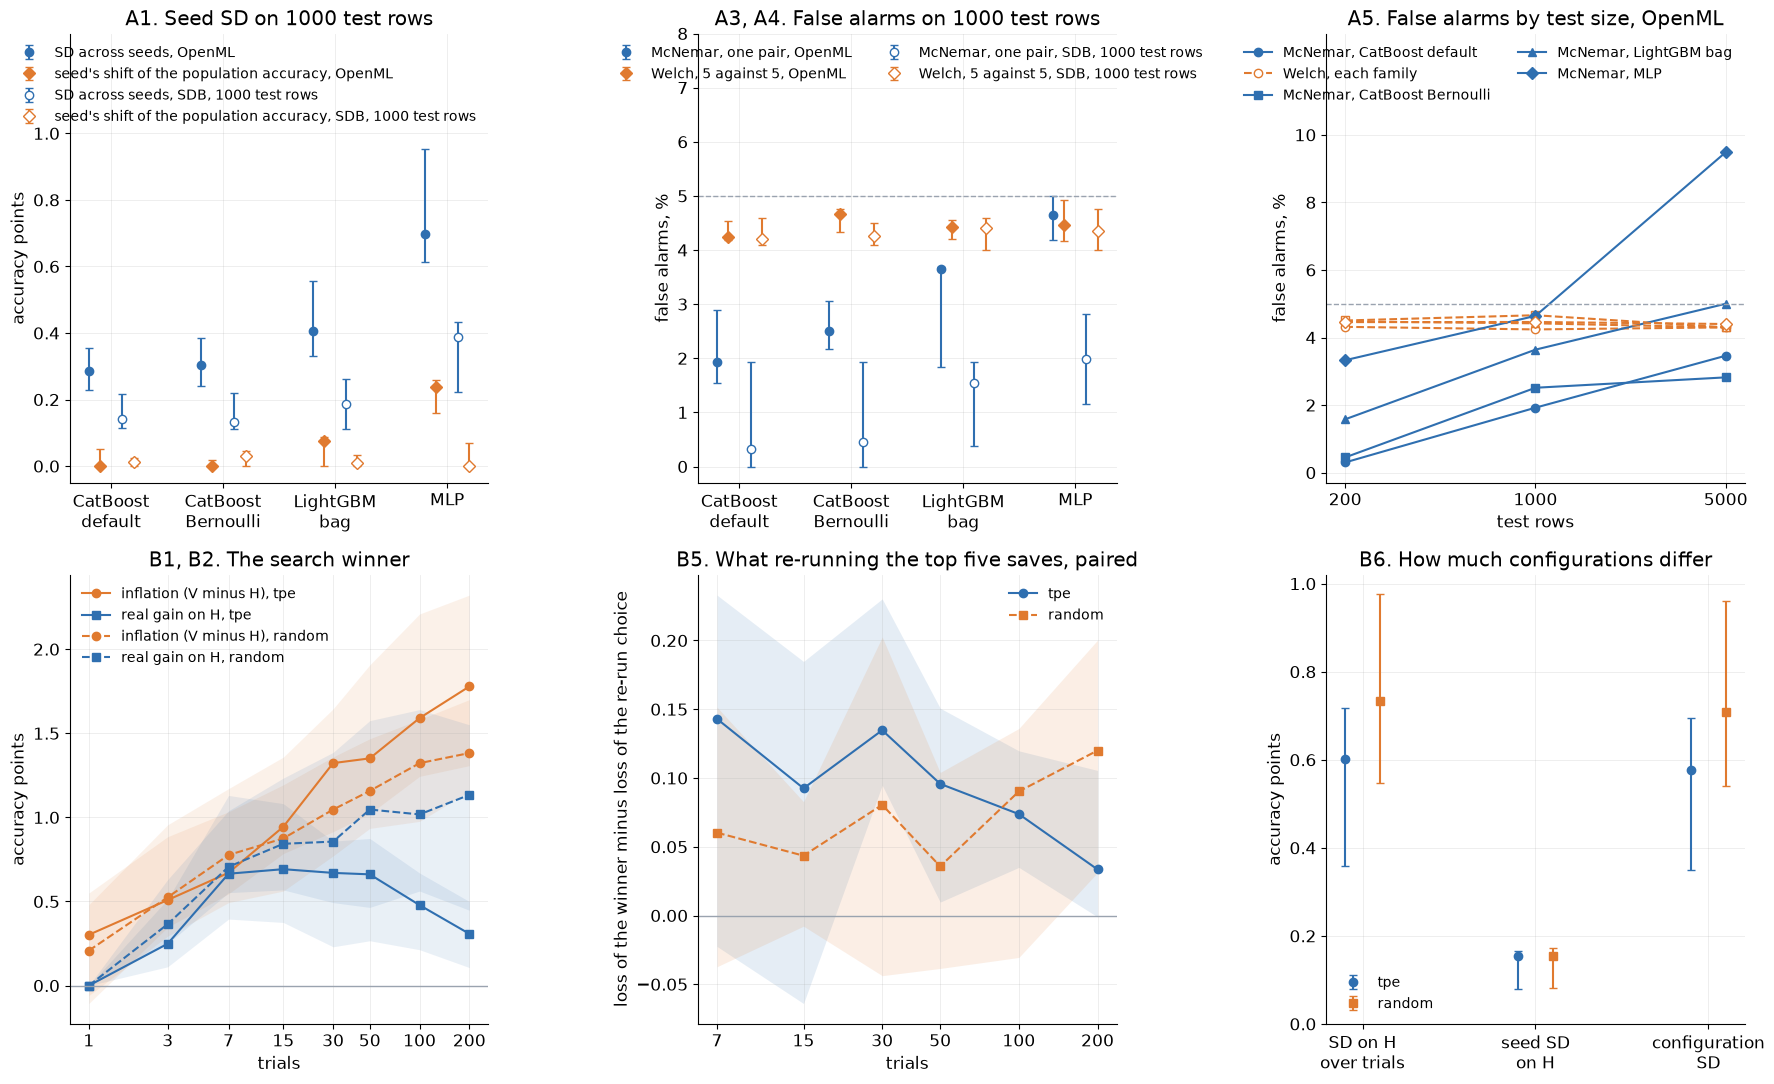

In [18]:
BLUE, ORANGE, GREY, INK, MUTED = "#2F6FB0", "#E07A2F", "#9AA3AF", "#1F2933", "#5B6573"
LABEL = {"catboost": "CatBoost default", "catboost_sub": "CatBoost Bernoulli", "lightgbm_bag": "LightGBM bag", "mlp": "MLP"}

def ci_err(frame, m, scale=100):
    return np.vstack([frame[m] - frame[m + "_lo"], frame[m + "_hi"] - frame[m]]) * scale

plt.rcParams.update({"font.size": 12})
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
x = np.arange(len(FAMILIES))

def family_panel(ax, *metrics):
    # two metrics by family on 1000 test rows, told apart by colour and marker;
    # filled markers OpenML, open markers SmallDataBenchmarks
    for k, (data, dx) in enumerate((("OpenML", -0.15), ("SDB, 1000 test rows", 0.15))):
        f = SUM_A[(SUM_A.data == data) & (SUM_A.test_rows == 1000)].set_index("family").loc[FAMILIES].reset_index()
        for (m, label), color, mk, off in zip(metrics, (BLUE, ORANGE), ("o", "D"), (-0.05, 0.05)):
            ax.errorbar(x + dx + off, f[m] * 100, ci_err(f, m), fmt=mk, color=color, mfc=color if k == 0 else "white",
                        capsize=3, label=f"{label}, {data}")

ax = axes[0, 0]   # A1
family_panel(ax, ("sd_seed", "SD across seeds"), ("sd_shift", "seed's shift of the population accuracy"))
ax.set(xticks=x, xticklabels=[LABEL[f].replace(" ", "\n", 1) for f in FAMILIES], ylabel="accuracy points",
       ylim=(-0.05, 1.3), yticks=np.arange(0, 1.01, 0.2), title="A1. Seed SD on 1000 test rows")
ax.legend(fontsize=10, frameon=False)

ax = axes[0, 1]   # A3, A4
family_panel(ax, ("mcnemar", "McNemar, one pair"), ("welch", "Welch, 5 against 5"))
ax.axhline(5, color=GREY, ls="--", lw=1)
ax.set(xticks=x, xticklabels=[LABEL[f].replace(" ", "\n", 1) for f in FAMILIES], ylabel="false alarms, %", ylim=(-0.3, 8),
       title="A3, A4. False alarms on 1000 test rows")
ax.legend(fontsize=10, frameon=False, loc="upper center", ncol=2)

ax = axes[0, 2]   # A5
for fam, mk in zip(FAMILIES, "os^D"):
    f = SUM_A[(SUM_A.data == "OpenML") & (SUM_A.family == fam)]
    ax.plot(f.test_rows, f.mcnemar * 100, marker=mk, color=BLUE, label=f"McNemar, {LABEL[fam]}")
    ax.plot(f.test_rows, f.welch * 100, marker=mk, color=ORANGE, ls="--", mfc="white",
            label="Welch, each family" if fam == FAMILIES[0] else None)
ax.axhline(5, color=GREY, ls="--", lw=1)
ax.set(xscale="log", xlabel="test rows", ylabel="false alarms, %", ylim=(-0.3, 13), yticks=range(0, 11, 2),
       title="A5. False alarms by test size, OpenML")
ax.minorticks_off()
ax.set_xticks(SIZES, SIZES)
ax.legend(fontsize=10, frameon=False, ncol=2)

ax = axes[1, 0]   # B1, B2
for s, ls in (("tpe", "-"), ("random", "--")):
    f = SUM_B[SUM_B.sampler == s]
    for m, color, mk, name in (("inflation", ORANGE, "o", "inflation (V minus H)"), ("gain", BLUE, "s", "real gain on H")):
        ax.plot(f["T"], f[m] * 100, ls=ls, marker=mk, color=color, label=f"{name}, {s}")
        ax.fill_between(f["T"], f[m + "_lo"] * 100, f[m + "_hi"] * 100, color=color, alpha=0.1, lw=0)
ax.axhline(0, color=GREY, lw=1)
ax.set(xscale="log", xlabel="trials", ylabel="accuracy points", title="B1, B2. The search winner")
ax.minorticks_off()
ax.set_xticks(PREFIXES, PREFIXES)
ax.legend(fontsize=10, frameon=False)

ax = axes[1, 1]   # B5, paired
for s, ls, mk, color in (("tpe", "-", "o", BLUE), ("random", "--", "s", ORANGE)):
    f = SUM_B[(SUM_B.sampler == s) & (SUM_B["T"] >= 7)]
    ax.plot(f["T"], f.cut * 100, ls=ls, marker=mk, color=color, label=s)
    ax.fill_between(f["T"], f.cut_lo * 100, f.cut_hi * 100, color=color, alpha=0.12, lw=0)
ax.axhline(0, color=GREY, lw=1)
ax.set(xscale="log", xlabel="trials", ylabel="loss of the winner minus loss of the re-run choice",
       title="B5. What re-running the top five saves, paired")
ax.minorticks_off()
ax.set_xticks(PREFIXES[2:], PREFIXES[2:])
ax.legend(fontsize=10, frameon=False)

ax = axes[1, 2]   # B6
ms = ["sd_h", "sd_seed", "sd_config"]
for k, (s, mk, color) in enumerate((("tpe", "o", BLUE), ("random", "s", ORANGE))):
    f = SUM_B6[SUM_B6.sampler == s]
    ax.errorbar(np.arange(3) + (k - 0.5) * 0.2, [f[m].iloc[0] * 100 for m in ms],
                np.hstack([ci_err(f, m) for m in ms]), fmt=mk, color=color, capsize=3, label=s)
ax.set(xticks=range(3), xticklabels=["SD on H\nover trials", "seed SD\non H", "configuration\nSD"],
       ylabel="accuracy points", ylim=(0, None), title="B6. How much configurations differ")
ax.legend(fontsize=10, frameon=False)

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.25, lw=0.6)
fig.tight_layout()
fig.savefig("model_comparison_run_noise.png", dpi=120, facecolor="white")
plt.show()
plt.rcParams.update({"font.size": 10})

The figure for the post: 1080 by 1350 pixels, two panels. Panel A is CatBoost with default
parameters on 1000 test rows, one point per dataset or family with a full 1000-row test set (the
OpenML datasets and the SmallDataBenchmarks families that have one), without the datasets where
all runs are identical. Its median pools the two sources; the cell prints them apart. Panel B is
the TPE search, the Optuna default: the winner's gain over the first trial, as the search reports it
(V) and as a fresh set shows it (H), from B4b. It has no bands: the two medians' intervals overlap
because the datasets differ a lot in level, but the comparison is paired, and the reported gain is
above the held-out gain on every dataset.

       mcnemar       welch     
        median size median size
source                         
OpenML    1.92    9   4.24    9
SDB       0.32   32   4.21   32
pooled median, %: {'mcnemar': 1.28, 'welch': 4.22}


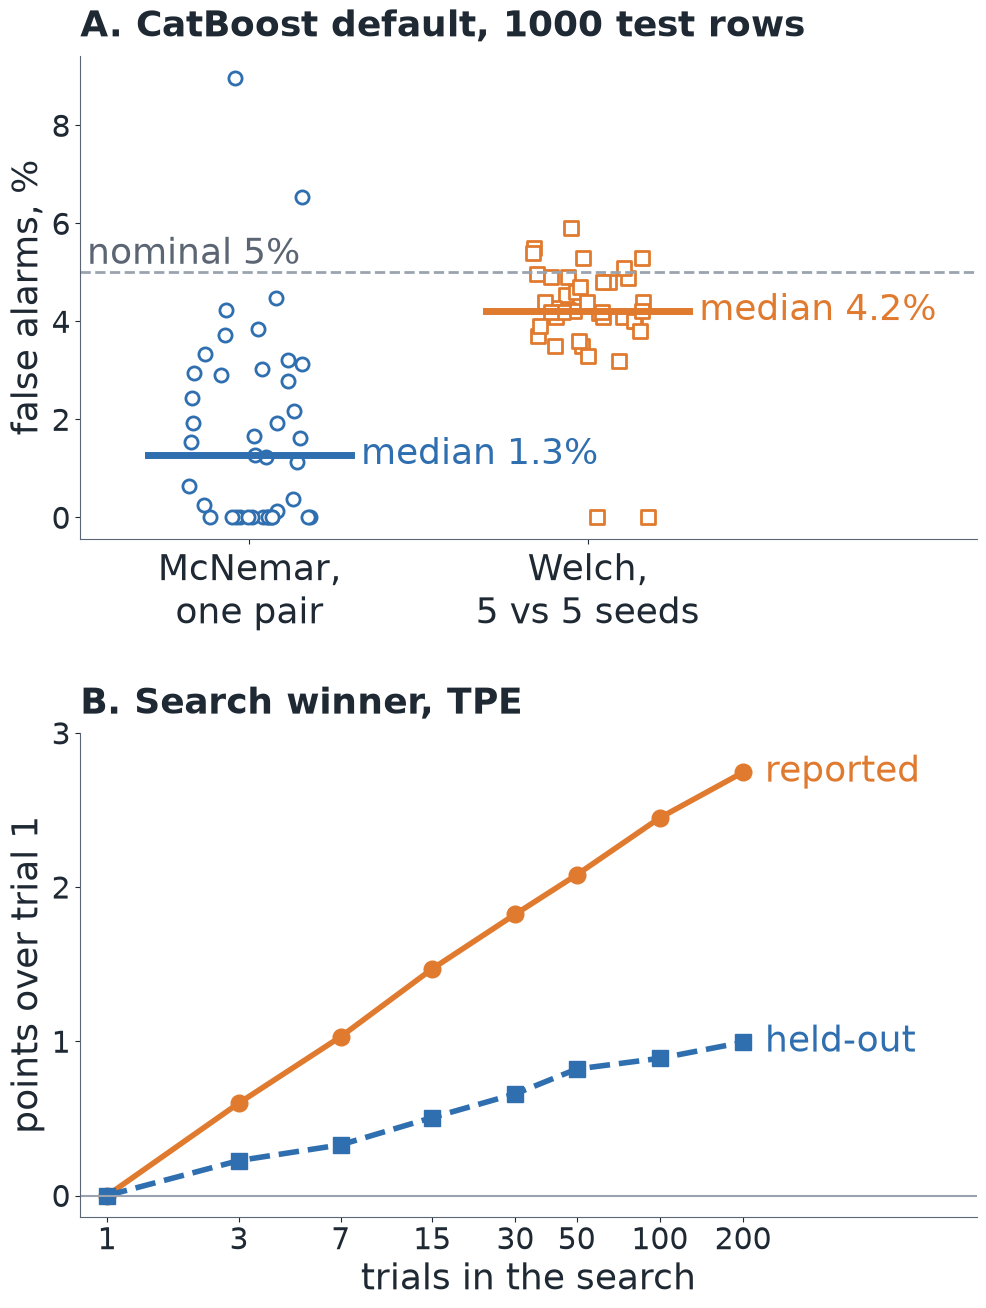

In [19]:
PX = 72 / 100                                  # points per pixel at 100 dpi
TXT, TICK = 36 * PX, 30 * PX
POST_STYLE = {"font.size": TXT, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
              "text.color": INK, "axes.edgecolor": MUTED}
with plt.rc_context(POST_STYLE):
    fig, (pa, pb) = plt.subplots(2, 1, figsize=(10.8, 13.5), dpi=100, gridspec_kw={"hspace": 0.4})
    fig.subplots_adjust(top=0.94, bottom=0.08, left=0.14, right=0.97)

    pts = pd.concat([PER_DATASET[(PER_DATASET.source == "openml") & (PER_DATASET.test_rows == 1000)],
                     UNITS["SDB, 1000 test rows"].groupby(["unit", "family"])[["mcnemar", "welch"]].mean().reset_index()])
    pts = pts[pts.family == "catboost"].dropna(subset=["mcnemar", "welch"])
    print(pts.assign(source=pts.unit.isna().map({True: "OpenML", False: "SDB"}))
          .groupby("source")[["mcnemar", "welch"]].agg(["median", "size"]).mul([100, 1, 100, 1]).round(2).to_string())
    print("pooled median, %:", (pts[["mcnemar", "welch"]].median() * 100).round(2).to_dict())
    rng = np.random.default_rng(0)
    for i, (m, color, mk) in enumerate((("mcnemar", BLUE, "o"), ("welch", ORANGE, "s"))):
        y = pts[m].to_numpy() * 100
        pa.scatter(i + rng.uniform(-0.18, 0.18, len(y)), y, s=90, marker=mk, facecolor="white", edgecolor=color, lw=2)
        pa.plot([i - 0.3, i + 0.3], [np.median(y)] * 2, color=color, lw=5)
        pa.text(i + 0.33, np.median(y), f"median {np.median(y):.1f}%", va="center", fontsize=TXT, color=color)
    pa.axhline(5, color=GREY, ls="--", lw=2)
    pa.text(-0.48, 5, "nominal 5%", va="bottom", ha="left", fontsize=TXT, color=MUTED)
    pa.set_xticks([0, 1], ["McNemar,\none pair", "Welch,\n5 vs 5 seeds"], fontsize=TXT)
    pa.set_xlim(-0.5, 2.15)
    pa.set_ylabel("false alarms, %", fontsize=TXT)
    pa.tick_params(axis="y", labelsize=TICK)
    pa.text(0, 1.04, "A. CatBoost default, 1000 test rows", transform=pa.transAxes, fontsize=TXT, fontweight="bold")

    f = SUM_UP[SUM_UP.sampler == "tpe"]
    for m, color, mk, ls, name in (("reported_up", ORANGE, "o", "-", "reported"), ("winner_h_up", BLUE, "s", "--", "held-out")):
        pb.plot(f["T"], f[m] * 100, color=color, marker=mk, ls=ls, lw=4, ms=12)
        pb.text(f["T"].iloc[-1] * 1.2, f[m].iloc[-1] * 100, name, va="center", fontsize=TXT, color=color)
    pb.axhline(0, color=GREY, lw=1.5)
    pb.set_xscale("log")
    pb.minorticks_off()
    pb.set_xticks(PREFIXES, PREFIXES)
    pb.set_xlim(0.8, 1400)
    pb.set_yticks([0, 1, 2, 3])
    pb.tick_params(labelsize=TICK)
    pb.set_xlabel("trials in the search", fontsize=TXT)
    pb.set_ylabel("points over trial 1", fontsize=TXT)
    pb.text(0, 1.04, "B. Search winner, TPE", transform=pb.transAxes, fontsize=TXT, fontweight="bold")
    for ax in (pa, pb):
        ax.spines[["top", "right"]].set_visible(False)
    fig.savefig("model_comparison_run_noise_linkedin.png", dpi=100, facecolor="white")
plt.show()

## Deviations

The design above was not changed. Added to the analysis, not listed in the design cell:

- `flip_ratio` (A1), after the split-half shift came out near zero.
- The per-dataset 95% Wilson intervals on disjoint pairs and groups (A3, A4), written while the
  experiments were running, before any result was read.
- The SmallDataBenchmarks summary restricted to the datasets with 1000 test rows.
- Datasets where all 40 runs are right on exactly the same rows are left out of the false alarm
  rates, because neither test can fire there. They are listed in the output above.
- The net inflation (B1), the paired cut of the re-run selection (B5) and the Spearman correlations
  between V and H (B6).
- The per-dataset McNemar rates above 5% at 5000 test rows (A5).
- The post figure's panel A pools the OpenML datasets and the SmallDataBenchmarks families into one
  median; the cell prints both sources apart.
- The gain over the first trial (B4b), written after the results were read. It replaced the
  inflation and real gain in the post figure's panel B.

Clarifications of the design:

- CatBoost's default on CPU already samples rows: MVS with `subsample=0.8` on binary data, the
  Bayesian bootstrap on multiclass data. The second CatBoost family differs by Bernoulli row sampling
  and feature sampling (`rsm=0.8`), not by sampling as such.
- Optuna's TPE starts with 10 random trials drawn with the same seed as `RandomSampler`, so both
  samplers run the same first 10 configurations.
- LightGBM ran with `force_row_wise=True`.
- The determinism check ran the second seed-0 fit as a separate pool task. That usually means a
  separate worker process, but the pool does not guarantee it, so the column name
  `two_processes_identical` says more than the check does.
- V has 1000 rows, so ties for the best V happen; they go to the earlier trial, as designed.
- On credit-default the pool outside H has 10 000 rows, so its studies share most of their rows.
- Experiment B made 14 455 re-runs, against about 10 000 estimated.

The post figure's choice of data (CatBoost with default parameters, 1000 test rows, TPE) was written
down while the experiments were running, before any result was read.

## What this measured

On the three datasets checked, on one machine, the same seed reproduced every prediction bit for
bit, for all four families. Within that scope every difference between runs below comes from the
seed.

For the three tree ensembles no shift of the population accuracy by the seed is detectable. The
split-half estimate is close to zero, and on about half of the datasets it is not even positive.
What the seed does move is which of the few unstable rows a run gets right, and `flip_ratio` near 1
says these rows flip about independently. So the SD across seeds on one test set behaves like row
noise and falls with the square root of the test size. The MLP disagrees with itself on many more
rows, and its seed does shift the population accuracy, on the large datasets and on
SmallDataBenchmarks as a whole, though not on its 1000-row subset. On the large datasets all of this
is for training sets of 5000 rows.

That decides what McNemar's test does on two seeds of one procedure. Two tree runs differ on so few
rows that the exact test can rarely reject: on 200 rows there are only a few discordant rows, and
the false alarm rate is far below nominal. The rate climbs towards nominal as the test set grows.
It goes above nominal where the seed shifts the accuracy itself: for the MLP at 5000 rows, and at
5000 rows on several single tree datasets, all with `flip_ratio` above 1 (the list in A5). So the
median shift of the trees is near zero, but not on every dataset. The median tree family stays at or
below nominal up to 5000 rows. Welch's test on five seeds against five stays close to its nominal
rate, as expected when the 40 seeds are exchangeable, and slightly below it, as Welch's test with
five against five is even on normal data.

In the search, the winner's score on V runs further ahead of the same run on H the more trials
there are, for both samplers, and the net inflation, with the offset of the V draw taken out, grows
the same way. With Random search the winner's real gain over the average trial grows slowly. With
TPE it rises over the first few trials, stays flat up to about 50 and then shrinks, because TPE's
later trials are better and lift the average. Up to 10 trials both samplers run the same
configurations, so differences there are seed noise. From 50 to 200 trials the reported score moves
several times more than the winner's accuracy on H, for both samplers. Over all 200 trials V and H
rank the trials moderately alike, but among the 40 best by V, where the winner is picked, the
correlation is weak (B6): there the noise in V decides more than the configuration does.

Re-running the top five with fresh seeds and choosing on fresh rows lowers the loss against the best
trial. With the mean H of the fresh runs as the reference, the paired cut is 0.04 to 0.19 points at
the median over datasets and positive on 5 to 8 of the 8 datasets; its interval excludes zero from 30
trials on for TPE and from 50 on for Random, not below. With the search run's own H the cut is
smaller, and its interval includes zero in most budgets (B5). It costs 25 more fits and two more
sets of 1000 labelled rows. Part of the remaining
loss cannot be recovered by any selection: the best trial on H is the maximum of many runs, each with
its own seed, so it is ahead partly by luck. The mean on V2, where the choice was made, stays
optimistic; the mean on V3, used for no choice, carries only its own draw offset.

Not measured here: non-deterministic GPU kernels and LLM sampling at temperature 0.